In [1]:
from keras import layers, models
import keras
from keras.datasets import imdb
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

I0000 00:00:1792145276.142145   11711 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Encode sentiments from pos/neg to 1/0

In [2]:
df = pd.read_csv('./datasets/IMDBDataset.csv')
df['sentiment'] = (df['sentiment'] == 'positive').astype(int)

## CountVectorizer() is used to generate bag of words

In [3]:
vec = CountVectorizer(max_features=10_000, binary=True)
X = vec.fit_transform(df['review']).astype('float32').toarray()
y = df['sentiment'].values

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

In [4]:
f = x_train[2500]
(f == 1).sum()

np.int64(81)

In [5]:
network = models.Sequential()
network.add(keras.Input((10000, )))
network.add(layers.Dense(16, activation='relu'))
network.add(layers.Dense(16, activation='relu'))
network.add(layers.Dense(1, activation='sigmoid'))

I0000 00:00:1792145320.218697   11711 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2603 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


### Since the problem and the output is classification-based we use cross entropy

In [6]:
network.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

## Building a validation set

In [7]:
x_validation = x_train[:10000]
x_train_partial = x_train[10000:]
y_validation = y_train[:10000]
y_partial_train = y_train[10000:]

In [15]:
history = network.fit(
    x_train_partial,
    y_partial_train,
    epochs=40,
    batch_size=512,
    validation_data=(x_validation, y_validation))

Epoch 1/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9961 - loss: 0.0163 - val_accuracy: 0.8630 - val_loss: 0.6304
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9996 - loss: 0.0067 - val_accuracy: 0.8624 - val_loss: 0.6490
Epoch 3/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9996 - loss: 0.0065 - val_accuracy: 0.8609 - val_loss: 0.6823
Epoch 4/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9974 - loss: 0.0101 - val_accuracy: 0.8569 - val_loss: 0.7551
Epoch 5/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9998 - loss: 0.0038 - val_accuracy: 0.8616 - val_loss: 0.7345
Epoch 6/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9999 - loss: 0.0033 - val_accuracy: 0.8612 - val_loss: 0.7655
Epoch 7/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9965 - loss: 0.0119 - val_accuracy: 0.8617 - val_loss: 0.7795
Epoch 8/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9999 - loss: 0.0025 - val_accuracy: 0.8611 - v

W0000 00:00:1792145501.858622   11711 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 20484096 bytes after encountering the first element of size 20484096 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 1.2526e-04 - val_accuracy: 0.8597 - val_loss: 1.2605
Epoch 35/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 1.1564e-04 - val_accuracy: 0.8597 - val_loss: 1.2743
Epoch 36/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 1.0731e-04 - val_accuracy: 0.8596 - val_loss: 1.2868
Epoch 37/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 1.0010e-04 - val_accuracy: 0.8598 - val_loss: 1.2990
Epoch 38/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 9.3778e-05 - val_accuracy: 0.8596 - val_loss: 1.3102
Epoch 39/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 8.8171e-05 - val_accuracy: 0.8596 - val_loss: 1.3208
Epoch 40/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 8.3175e-05 - val_accuracy: 0.8595 - val_loss: 1.3311


In [9]:
hist = history.history
hist.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [10]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']

loss_values

[0.5267505049705505,
 0.31660696864128113,
 0.24058951437473297,
 0.1922287940979004,
 0.16191937029361725,
 0.1391933113336563,
 0.11751702427864075,
 0.09916102886199951,
 0.08517058938741684,
 0.0760527104139328,
 0.06249097362160683,
 0.05439457297325134,
 0.04430306330323219,
 0.041030075401067734,
 0.032926082611083984,
 0.03099355660378933,
 0.019781824201345444,
 0.01810360513627529,
 0.018947087228298187,
 0.011959643103182316]

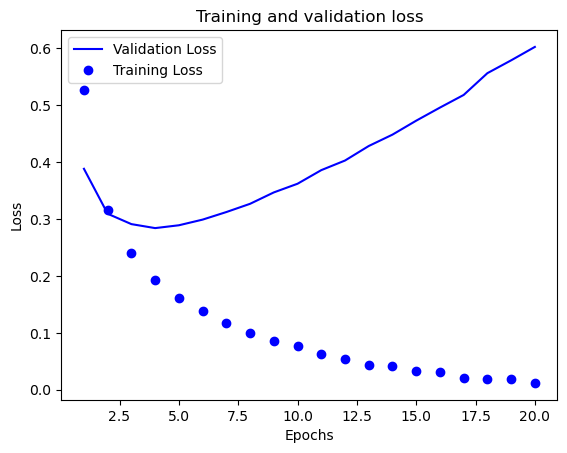

In [11]:
import matplotlib.pyplot as plt


acc = history_dict['accuracy']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, val_loss_values, 'b', label='Validation Loss')
plt.plot(epochs, loss_values, 'bo', label='Training Loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

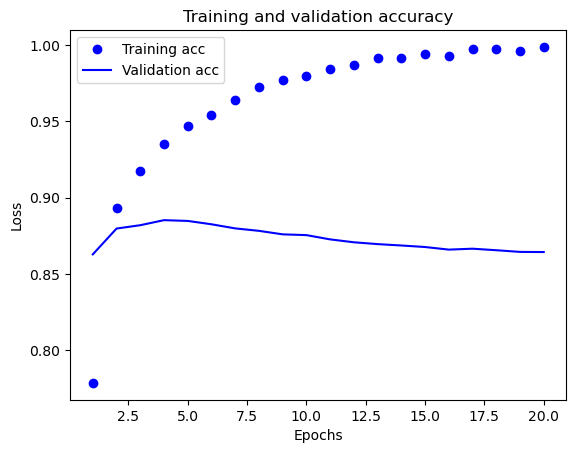

In [12]:
plt.clf()
acc_values = history_dict['accuracy']
val_acc_values = history_dict['val_accuracy']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc_values, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [13]:
model = models.Sequential()
model.add(layers.Dense(16, activation='relu', input_shape=(10000,)))
model.add(layers.Dense(16, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

model.compile(optimizer='rmsprop',
loss='binary_crossentropy',
metrics=['accuracy'])


model.fit(x_train, y_train, epochs=4, batch_size=512)
results = model.evaluate(x_test, y_test)
results

/home/devalireza/.local/lib/python3.14/site-packages/keras/src/layers/core/dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1792145349.240220   11711 cpu_allocator_impl.cc:174] Allocation of 1000000000 exceeds 10% of free system memory.


Epoch 1/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8064 - loss: 0.4831
Epoch 2/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8983 - loss: 0.2835
Epoch 3/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9194 - loss: 0.2215
Epoch 4/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9288 - loss: 0.1900
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8872 - loss: 0.2871


[0.28712141513824463, 0.8871600031852722]

In [14]:
y_pred = model.predict(x_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
